<a href="https://colab.research.google.com/github/snatzehua/bt-4012-project-2026/blob/feat--zs-exploration-00/notebooks/11_results_synthesis_and_conclusions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BT4012 · 11 · Results synthesis and conclusions

**Purpose:** provide a readable endpoint for this branch: what we investigated, what the evidence shows, the model selected during development, and its practical limitations.

This notebook reads the CSV/JSON results already produced by notebooks 02–10. It does **not** train models, load model binaries, read raw applications, optimise thresholds, tune weights, or select a new model using holdout results.

**Reading order:** experiment overview → development findings → reserved-period model evaluation → update-policy findings → workload implications → recommendation and limitations.

**Evidence boundaries:**

- Notebooks 02–08 use month 5 for development; repeated use means their gains are not independent confirmations.
- Notebook 09 uses months 3–5 retrospectively with an already selected configuration. It is a development backtest.
- Notebook 10 evaluates the predefined choices on months 6–7. A teammate had already inspected those months; disclose that exposure.
- Month 6 labels calibrate the adaptive policies' month-7 cutoffs under an explicit outcome-availability assumption. Month 7 provides only one new policy update comparison.

The report text below is calculated from the chosen result files. Review it alongside the tables before copying it into the group report. It deliberately does not invent significance tests, financial savings or a real deployment.


## 1. Project directory and input runs

Colab defaults to `MyDrive/BT4012_grp_proj`. Locally run from the repository's `notebooks/` directory or set `LOCAL_REPO_ROOT`.

Only the **results folders** are needed. No Base.csv, prepared parquet, prediction parquet or model files are loaded. Retain the JSON manifests beside the CSV summaries.

For each stage, leave its override as `None` if only one completed result folder exists. If several runs exist, the discovery cell lists them; copy the intended run folder path into `RUN_DIR_OVERRIDES` and rerun. Selection is never based on best score or latest timestamp.

Stage 02 is optional because older baseline exports may be unavailable; an omission is explicitly recorded. Stages 03–10 are required for the complete synthesis. Notebook 08 writes under `results/ensemble_averaging/`, using `ensemble_summary.csv`. Rerun the updated notebook 08 before this synthesis notebook.


In [ ]:
import sys
from pathlib import Path

# Detect the runtime; local execution does not require google.colab.
IN_COLAB = 'google.colab' in sys.modules

# Colab: keep Base.csv directly inside this existing Drive project folder.
DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/BT4012_grp_proj')

# Local: normally leave None; set an absolute repo path if auto-detection fails.
LOCAL_REPO_ROOT = None

if IN_COLAB:
    from google.colab import drive

    drive.mount('/content/drive')
    PROJECT_DIR = DRIVE_PROJECT_DIR
    RAW_PATH = PROJECT_DIR / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'processed'
else:
    if LOCAL_REPO_ROOT is not None:
        PROJECT_DIR = Path(LOCAL_REPO_ROOT).expanduser().resolve()
    else:
        working_dir = Path.cwd().resolve()
        candidates = [working_dir, *working_dir.parents]
        PROJECT_DIR = next(
            (
                candidate
                for candidate in candidates
                if (candidate / 'notebooks').is_dir()
                and (candidate / 'data').is_dir()
            ),
            working_dir,
        )

    RAW_PATH = PROJECT_DIR / 'data' / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'


RESULTS_ROOT = PROJECT_DIR / 'results'
RUN_DIR_OVERRIDES = {
    '02': None,  # results/baseline/<run>
    '03': None,  # results/training_composition/<run>
    '04': None,  # results/imbalance_treatment/<run>
    '05': None,  # results/model_comparison/<run>
    '06': None,  # results/temporal_stacking/<run>
    '07': None,  # results/temporal_domain_adaptation/<run>
    '08': None,  # results/ensemble_averaging/<run>
    '09': None,  # results/monthly_retraining/<run>
    '10': None,  # results/temporal_holdout/<run>
}
print('Read existing results from:', RESULTS_ROOT)


Mounted at /content/drive
Read existing results from: /content/drive/MyDrive/BT4012_grp_proj/results


## 2. Lightweight dependencies and source discovery

Only `numpy`, `pandas`, `matplotlib` and IPython are required. No CatBoost, LightGBM, sklearn or parquet engine is needed. A complete input run must contain the specified summary files and metadata. Partial runs are listed separately rather than silently combined.


In [ ]:
import importlib.util
import subprocess

packages = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib'}
missing = [p for name, p in packages.items() if importlib.util.find_spec(name) is None]
if missing:
    if IN_COLAB:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
    else:
        raise ImportError('Install: python -m pip install ' + ' '.join(missing))

import json
import hashlib
from datetime import datetime, timezone
from uuid import uuid4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

STAGES = {
    '02': ('baseline', 'run_info.json', ['validation_metrics.csv']),
    '03': ('training_composition', 'run_info.json', ['condition_summary.csv', 'paired_summary.csv']),
    '04': ('imbalance_treatment', 'run_info.json', ['condition_summary.csv']),
    '05': ('model_comparison', 'run_info.json', ['final_development_summary.csv', 'ensemble_input_manifest.json']),
    '06': ('temporal_stacking', 'run_info.json', ['stacking_summary.csv']),
    '07': ('temporal_domain_adaptation', 'run_manifest.json', ['validation_summary.csv', 'domain_feature_importance.csv']),
    '08': ('ensemble_averaging', 'ensemble_recipes.json', ['validation_metrics.csv', 'ensemble_summary.csv']),
    '09': ('monthly_retraining', 'run_manifest.json', ['monthly_policy_metrics.csv', 'policy_aggregate.csv']),
    '10': ('temporal_holdout', 'run_manifest.json', [
        'static_model_metrics.csv', 'monthly_policy_metrics.csv', 'policy_aggregate_deployed.csv',
        'review_capacity_aggregate.csv', 'threshold_history.json', 'model_fit_cost.csv',
    ]),
}


def inspect_run(folder, stage):
    """Return eligibility and a reason; never choose a run based on its metrics."""
    _, metadata_file, files = STAGES[stage]
    absent = [f for f in [metadata_file, *files] if not (folder / f).is_file()]
    if absent:
        return False, 'Missing: ' + ', '.join(absent)
    try:
        info = json.loads((folder / metadata_file).read_text())
    except (ValueError, OSError) as exc:
        return False, 'Cannot read metadata: ' + str(exc)
    if info.get('status') not in (None, 'complete'):
        return False, 'Run status: ' + str(info.get('status'))
    return True, 'complete summaries'


runs, discovery_rows, problems = {}, [], []
for stage, (subdir, _, _) in STAGES.items():
    override = RUN_DIR_OVERRIDES[stage]
    candidates = [Path(override).expanduser().resolve()] if override else sorted(
        p for p in (RESULTS_ROOT / subdir).glob('*') if p.is_dir())
    eligible = []
    for folder in candidates:
        ok, reason = inspect_run(folder, stage)
        discovery_rows.append({'stage': stage, 'folder': str(folder), 'eligible': ok, 'reason': reason})
        if ok:
            eligible.append(folder)
    if len(eligible) == 1:
        runs[stage] = eligible[0]
    elif stage == '02' and not eligible and override is None:
        print('Stage 02 baseline export unavailable: explicitly omitted from the historical table.')
    else:
        problems.append(f'Stage {stage}: {len(eligible)} eligible runs; set its RUN_DIR_OVERRIDES entry.')

display(pd.DataFrame(discovery_rows))
if problems:
    raise ValueError('\n'.join(problems))
print('Selected run folders:')
for stage, folder in runs.items():
    print(stage, folder)


,stage,folder,eligible,reason
0,02,/content/drive/MyDrive/BT4012_grp_proj/results...,True,complete summaries
1,03,/content/drive/MyDrive/BT4012_grp_proj/results...,True,complete summaries
2,04,/content/drive/MyDrive/BT4012_grp_proj/results...,True,complete summaries
3,05,/content/drive/MyDrive/BT4012_grp_proj/results...,True,complete summaries
4,06,/content/drive/MyDrive/BT4012_grp_proj/results...,True,complete summaries
5,07,/content/drive/MyDrive/BT4012_grp_proj/results...,True,complete summaries
6,08,/content/drive/MyDrive/BT4012_grp_proj/results...,True,complete summaries
7,09,/content/drive/MyDrive/BT4012_grp_proj/results...,True,complete summaries
8,10,/content/drive/MyDrive/BT4012_grp_proj/results...,True,complete summaries


Selected run folders:
02 /content/drive/MyDrive/BT4012_grp_proj/results/baseline/unweighted_baseline_20261115T161531Z_103e88
03 /content/drive/MyDrive/BT4012_grp_proj/results/training_composition/training_composition_unweighted_20261115T175457Z_55dcc3
04 /content/drive/MyDrive/BT4012_grp_proj/results/imbalance_treatment/imbalance_all_history_20261115T182353Z_5d20b0
05 /content/drive/MyDrive/BT4012_grp_proj/results/model_comparison/model_comparison_20261115T184401Z_8e91a0
06 /content/drive/MyDrive/BT4012_grp_proj/results/temporal_stacking/temporal_stack_20261115T195110Z_f62256
07 /content/drive/MyDrive/BT4012_grp_proj/results/temporal_domain_adaptation/temporal_domain_adaptation_20261117T151240Z_2f93c8
08 /content/drive/MyDrive/BT4012_grp_proj/results/ensemble_averaging/20261117T165516Z_45fd26
09 /content/drive/MyDrive/BT4012_grp_proj/results/monthly_retraining/20261117T155430Z_2496ed
10 /content/drive/MyDrive/BT4012_grp_proj/results/temporal_holdout/20261117T161329Z_88d26a


## 3. Provenance and analysis helpers

Check that the runs reference the same prepared data. Verify notebook 08's recorded input-manifest hash against the selected notebook-05 manifest, so predictions from a different model-comparison run are not silently attributed to it.

The earlier notebooks are independent experiments; their metrics should be compared within their respective designs. A small mismatch between earlier validation scores and notebook 10's refitted models can arise from changed package versions; this notebook reports source provenance rather than forcing numerical agreement.


In [ ]:
input_inventory = []


def digest(path):
    """Hash input files so the exported synthesis can be traced to exact sources."""
    h = hashlib.sha256()
    with open(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


def record_source(stage, filename):
    path = runs[stage] / filename
    entry = {'stage': stage, 'file': filename, 'path': str(path), 'sha256': digest(path)}
    if not any(x['path'] == entry['path'] for x in input_inventory):
        input_inventory.append(entry)
    return path


def read_json(stage, filename):
    return json.loads(record_source(stage, filename).read_text())


def read_table(stage, filename, required=()):
    """Read one saved CSV; fail explicitly if a required schema field is absent."""
    table = pd.read_csv(record_source(stage, filename))
    absent = set(required) - set(table.columns)
    if absent:
        raise ValueError(f'{stage}/{filename} missing columns: {sorted(absent)}')
    return table


metadata = {stage: read_json(stage, STAGES[stage][1]) for stage in runs}
hashes = {stage: item.get('prepared_sha256') for stage, item in metadata.items()}
if any(not value for value in hashes.values()) or len(set(hashes.values())) != 1:
    raise ValueError('Input runs must all identify the same prepared_sha256; review selected runs.')
if metadata['08'].get('input_manifest_sha256') != digest(runs['05'] / 'ensemble_input_manifest.json'):
    raise ValueError('Notebook 08 used a different notebook-05 manifest. Select matching runs.')
assert metadata['10']['evaluation_months'] == [6, 7]

run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
OUTPUT_DIR = RESULTS_ROOT / 'results_synthesis' / run_id
TABLES_DIR, FIGURES_DIR = OUTPUT_DIR / 'tables', OUTPUT_DIR / 'figures'
TABLES_DIR.mkdir(parents=True, exist_ok=False)
FIGURES_DIR.mkdir()
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 200})
report_sections = []


def table_markdown(table):
    """Small dependency-free Markdown table formatter for report export."""
    def fmt(value):
        if pd.isna(value):
            return '—'
        if isinstance(value, (float, np.floating)):
            return f'{value:.5f}'
        return str(value).replace('|', '/').replace('\n', ' ')
    headers = [str(c) for c in table.columns]
    lines = ['| ' + ' | '.join(headers) + ' |', '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines += ['| ' + ' | '.join(fmt(v) for v in row) + ' |' for row in table.itertuples(index=False, name=None)]
    return '\n'.join(lines)


def section(title, prose, table=None, filename=None):
    """Display and collect a report section; optionally export its supporting table."""
    text = '## ' + title + '\n\n' + prose
    display(Markdown(text))
    if table is not None:
        display(table)
        text += '\n\n' + table_markdown(table)
        if filename:
            table.to_csv(TABLES_DIR / filename, index=False)
    report_sections.append(text)


def one_row(table, column, value):
    rows = table[table[column].eq(value)]
    if len(rows) != 1:
        raise ValueError(f'Expected one row where {column}={value!r}; got {len(rows)}.')
    return rows.iloc[0]


def pp(value):
    return f'{100 * value:+.2f} percentage points'


print('Synthesis output:', OUTPUT_DIR)


Synthesis output: /content/drive/MyDrive/BT4012_grp_proj/results/results_synthesis/20261117T165638Z_67f7c4


## 4. Experiment overview and development record

The development sequence is a set of related experiments, not one fair all-model leaderboard. Models, data subsets, seeds and selection stages differ. Preserve the paired controls inside each experiment.

The selected recipe is a historical decision from validation: three equally weighted CatBoost models trained on independent 10:1 undersamples of all eligible history. The synthesis does not reselect that recipe using months 6–7.


In [ ]:
overview = pd.DataFrame([
    ['02', 'Initial baseline', 'LR / LightGBM / dummy', 'Month 5', 'Establish reference models and metrics'],
    ['03', 'Training composition', 'All history vs recent K vs random historical K', 'Month 5', 'Separate recency from eligible sample size'],
    ['04', 'Class imbalance', 'No treatment / class weights / undersampling ratios', 'Month 5', 'Compare AP, capture and training time'],
    ['05', 'Model families', 'LR / LightGBM / CatBoost / XGBoost, plus transfer check', 'Month 5', 'Compare bounded family configurations'],
    ['06', 'Temporal stacking', 'Forward-fold meta-model and simple averaging', 'Month 5', 'Assess incremental value of learned combination'],
    ['07', 'Domain adaptation', 'Historical relevance weights toward month 4', 'Month 5', 'Test whether population matching helps prediction'],
    ['08', 'Ensemble averaging', 'Seed means and fixed cross-family means', 'Month 5', 'Compare fixed prediction averages'],
    ['09', 'Update policies', 'Frozen / threshold only / retrain + threshold', 'Months 3–5, development', 'Separate ranking from threshold maintenance'],
    ['10', 'Temporal evaluation', 'Predefined model and policy comparisons', 'Months 6–7', 'Assess how prior choices carry forward'],
], columns=['notebook', 'experiment', 'comparison', 'evaluation_period', 'purpose'])
section('Experiment map', 'Development and reserved-period evaluation are kept separate throughout this synthesis.',
        overview, 'experiment_overview.csv')

if '02' in runs:
    baseline = read_table('02', 'validation_metrics.csv', ['model', 'average_precision'])
    cols = [c for c in ['model', 'average_precision', 'roc_auc', 'recall_at_target_fpr_benchmark', 'fit_seconds'] if c in baseline]
    section('02 · Initial baseline', 'Original baseline validation results; these are not holdout measurements.',
            baseline[cols], '02_baseline_validation.csv')
else:
    section('02 · Initial baseline', 'Original baseline result files were unavailable. No historical baseline numbers were invented. '
            'Notebook 10 separately refits the fixed LightGBM baseline for the reserved-period comparison.')

composition = read_table('03', 'condition_summary.csv', ['condition', 'ap_mean', 'ap_std', 'recall_at_fpr_mean'])
recency_pairs = read_table('03', 'paired_summary.csv', ['recent_condition', 'comparator', 'ap_delta_mean'])
all_history = one_row(composition, 'condition', 'all_history')
matched = recency_pairs[recency_pairs.comparator.str.startswith('historical_k')]
section('03 · Training-data composition',
    f"All-history LightGBM achieved mean validation AP {all_history.ap_mean:.5f} and recall@5%FPR "
    f"{all_history.recall_at_fpr_mean:.2%}. The paired table below isolates recent samples from same-size random history; "
    'do not interpret a recent-versus-all-history comparison alone as a pure recency effect.',
    composition, '03_composition_summary.csv')
section('03 · Same-size recency comparisons',
    f"Recent data had positive mean AP differences in {int((matched.ap_delta_mean > 0).sum())} of "
    f"{len(matched)} matched-size comparisons. This is descriptive evidence, not a significance test or proof that drift is absent.",
    matched, '03_matched_recency.csv')

imbalance = read_table('04', 'condition_summary.csv', ['condition', 'ap_mean', 'recall_at_fpr_mean', 'fit_seconds_mean'])
untreated = one_row(imbalance, 'condition', 'none')
rus = one_row(imbalance, 'condition', 'undersample_10to1')
section('04 · Imbalance treatment',
    f"Compared with no treatment, 10:1 undersampling changed mean AP by {rus.ap_mean - untreated.ap_mean:+.5f} "
    f"and recall@5%FPR by {pp(rus.recall_at_fpr_mean - untreated.recall_at_fpr_mean)}. "
    f"Mean fit times were {rus.fit_seconds_mean:.2f}s versus {untreated.fit_seconds_mean:.2f}s in this run. "
    'AP and recall need not move together. Undersampling changes training prevalence, so raw model scores should not be treated as calibrated population fraud probabilities.',
    imbalance, '04_imbalance_summary.csv')


## Experiment map

Development and reserved-period evaluation are kept separate throughout this synthesis.

,notebook,experiment,comparison,evaluation_period,purpose
0,02,Initial baseline,LR / LightGBM / dummy,Month 5,Establish reference models and metrics
1,03,Training composition,All history vs recent K vs random historical K,Month 5,Separate recency from eligible sample size
2,04,Class imbalance,No treatment / class weights / undersampling r...,Month 5,"Compare AP, capture and training time"
3,05,Model families,"LR / LightGBM / CatBoost / XGBoost, plus trans...",Month 5,Compare bounded family configurations
4,06,Temporal stacking,Forward-fold meta-model and simple averaging,Month 5,Assess incremental value of learned combination
5,07,Domain adaptation,Historical relevance weights toward month 4,Month 5,Test whether population matching helps prediction
6,08,Ensemble averaging,Seed means and fixed cross-family means,Month 5,Compare fixed prediction averages
7,09,Update policies,Frozen / threshold only / retrain + threshold,"Months 3–5, development",Separate ranking from threshold maintenance
8,10,Temporal evaluation,Predefined model and policy comparisons,Months 6–7,Assess how prior choices carry forward


## 02 · Initial baseline

Original baseline validation results; these are not holdout measurements.

,model,average_precision,roc_auc,recall_at_target_fpr_benchmark,fit_seconds
0,lightgbm,0.184986,0.895672,0.545004,34.194769
1,logreg,0.158263,0.883355,0.507442,10.792561
2,dummy,0.011825,0.500000,NaN,0.034425


## 03 · Training-data composition

All-history LightGBM achieved mean validation AP 0.18567 and recall@5%FPR 54.36%. The paired table below isolates recent samples from same-size random history; do not interpret a recent-versus-all-history comparison alone as a pure recency effect.

,condition,seeds,training_rows,fraud_rate_mean,ap_mean,ap_std,recall_at_fpr_mean,recall_at_fpr_std,achieved_fpr_mean,precision_at_fpr_mean,alert_rate_mean,fit_seconds_mean
0,all_history,3,675666,0.009975,0.185667,0.001342,0.543586,0.001417,0.049995,0.115131,0.055832,36.675630
1,historical_k_3m,3,415606,0.009964,0.182648,0.004925,0.540279,0.005366,0.049995,0.114510,0.055793,20.213383
2,recent_3m,3,415606,0.009726,0.181687,0.003021,0.536263,0.000818,0.049995,0.113756,0.055745,23.344374
3,historical_k_2m,3,278627,0.009930,0.176997,0.004424,0.533428,0.002165,0.049995,0.113223,0.055712,14.663725
4,recent_2m,3,278627,0.010207,0.176473,0.001325,0.536026,0.005505,0.049995,0.113711,0.055742,15.919299
5,historical_k_1m,3,127691,0.010230,0.167579,0.004062,0.517364,0.004961,0.049995,0.110188,0.055522,8.217293
6,recent_1m,3,127691,0.011371,0.167563,0.002406,0.516419,0.001083,0.049995,0.110010,0.055510,5.099480


## 03 · Same-size recency comparisons

Recent data had positive mean AP differences in 0 of 3 matched-size comparisons. This is descriptive evidence, not a significance test or proof that drift is absent.

,recent_condition,comparator,ap_delta_mean,ap_delta_std,recall_delta_mean,seeds_with_positive_ap_delta
0,recent_1m,historical_k_1m,-0.000016,0.005684,-0.000945,1
2,recent_2m,historical_k_2m,-0.000523,0.005731,0.002599,1
4,recent_3m,historical_k_3m,-0.000961,0.002078,-0.004016,1


## 04 · Imbalance treatment

Compared with no treatment, 10:1 undersampling changed mean AP by +0.00654 and recall@5%FPR by -0.24 percentage points. Mean fit times were 3.95s versus 30.43s in this run. AP and recall need not move together. Undersampling changes training prevalence, so raw model scores should not be treated as calibrated population fraud probabilities.

,condition,seeds,training_rows,positive_weight,fraud_rate_mean,ap_mean,ap_std,recall_at_fpr_mean,recall_at_fpr_std,achieved_fpr_mean,precision_at_fpr_mean,alert_rate_mean,fit_seconds_mean
0,undersample_10to1,3,74140,1.000000,0.090909,0.192209,0.001620,0.541224,0.005901,0.049995,0.114687,0.055804,3.952829
1,undersample_20to1,3,141540,1.000000,0.047619,0.190365,0.002716,0.540751,0.000709,0.049995,0.114599,0.055798,5.594026
2,undersample_1to1,3,13480,1.000000,0.500000,0.189653,0.003032,0.536499,0.002835,0.049995,0.113800,0.055748,0.804980
3,weight_full_ratio,3,675666,99.247181,0.009975,0.185682,0.002135,0.536263,0.004330,0.049995,0.113755,0.055745,34.925139
4,none,3,675666,1.000000,0.009975,0.185667,0.001342,0.543586,0.001417,0.049995,0.115131,0.055832,30.425341
5,weight_sqrt_ratio,3,675666,9.962288,0.009975,0.177552,0.005168,0.534845,0.006431,0.049995,0.113488,0.055728,29.902483


## 5. Model families, stacking, adaptation and averaging

Seed SD describes variability across the sampled fits, not a confidence interval. A one-seed experiment cannot establish seed stability. Ensemble AP is computed from averaged scores and must not be confused with the average of individual AP values.


In [ ]:
families = read_table('05', 'final_development_summary.csv', ['candidate', 'family', 'treatment', 'ap_mean', 'recall_at_fpr_mean'])
section('05 · Model-family comparison',
    'These are the selected bounded configurations and the full-data transfer comparison from notebook 05. '
    'Treat the screen and subsequent seed checks as development. This table includes different training treatments, so differences cannot all be attributed solely to model architecture.',
    families, '05_family_summary.csv')

stacking = read_table('06', 'stacking_summary.csv', ['candidate', 'seeds', 'ap_mean', 'recall_at_fpr_mean'])
stack = one_row(stacking, 'candidate', 'temporal_stack')
cat_reference = one_row(stacking, 'candidate', 'catboost_rus10')
section('06 · Temporal stacking',
    f"The temporal stack's AP difference from its CatBoost reference was {stack.ap_mean - cat_reference.ap_mean:+.5f}; "
    f"the recall@5%FPR difference was {pp(stack.recall_at_fpr_mean - cat_reference.recall_at_fpr_mean)}. "
    f"The stack was evaluated with {int(stack.seeds)} seed(s). A small improvement in one run does not demonstrate a reliable benefit from the added meta-model.",
    stacking, '06_stacking_summary.csv')

adaptation = read_table('07', 'validation_summary.csv', ['condition', 'ap_mean', 'recall_mean', 'ess_fraction_mean'])
base_adapt = one_row(adaptation, 'condition', 'unweighted')
adaptation['ap_difference_from_unweighted'] = adaptation.ap_mean - base_adapt.ap_mean
adaptation['recall_difference_from_unweighted'] = adaptation.recall_mean - base_adapt.recall_mean
section('07 · Temporal domain adaptation',
    'This experiment reweighted historical rows toward month 4 and evaluated month 5. The table reports differences from the matched unweighted control. '
    'Effective sample size measures weight concentration, not the number of independent fraud examples. A negative result applies to this scheme, not every possible adaptation method.',
    adaptation, '07_adaptation_summary.csv')
domain_importance = read_table('07', 'domain_feature_importance.csv', ['feature', 'mean_importance'])
velocity_importance = domain_importance.loc[domain_importance.feature.isin(['velocity_4w', 'velocity_24h', 'velocity_6h']), 'mean_importance'].sum()
section('07 · Adaptation diagnostic',
    f"The three velocity features account for {velocity_importance:.1f}% of the period classifier's reported importance. "
    'This suggests it largely distinguished periods using application-volume patterns. It does not prove that those variables caused the fraud-performance result.',
    domain_importance.head(10), '07_domain_top_features.csv')

averaging = read_table('08', 'validation_metrics.csv', ['name', 'average_precision', 'recall_at_5fpr', 'n_models'])
avg_summary = read_table('08', 'ensemble_summary.csv', ['predictor_group', 'evaluation', 'ap', 'recall'])
cat_mean = one_row(averaging, 'name', 'catboost_seed_mean')
cat_single = one_row(averaging, 'name', 'catboost_seed_42')
nine = one_row(averaging, 'name', 'all_nine_mean')
section('08 · Fixed averaging',
    f"The three-CatBoost mean achieved validation AP {cat_mean.average_precision:.5f}, versus {cat_single.average_precision:.5f} "
    f"for seed 42 and {nine.average_precision:.5f} for the nine-model mean. Its recall@5%FPR was {cat_mean.recall_at_5fpr:.2%}. "
    'The three-CatBoost average was carried forward based on development AP and smaller model count than the nine-model blend. '
    'This records the earlier choice; it does not select a new ensemble from holdout outcomes.',
    avg_summary, '08_averaging_summary.csv')


## 05 · Model-family comparison

These are the selected bounded configurations and the full-data transfer comparison from notebook 05. Treat the screen and subsequent seed checks as development. This table includes different training treatments, so differences cannot all be attributed solely to model architecture.

,candidate,family,treatment,seeds,training_rows,ap_mean,ap_std,recall_at_fpr_mean,recall_at_fpr_std,achieved_fpr_mean,precision_at_fpr_mean,fit_seconds_mean
0,cat_d4_n600,catboost,rus10,3,74140,0.196041,0.001335,0.545948,0.001784,0.049995,0.115573,57.298521
1,lgbm_rus10,lightgbm,rus10,3,74140,0.192209,0.001620,0.541224,0.005901,0.049995,0.114687,4.818374
2,cat_d4_n600_full_transfer,catboost,none,3,675666,0.192175,0.000839,0.545712,0.003089,0.049995,0.115529,519.734927
3,xgb_d3_n600,xgboost,rus10,3,74140,0.191927,0.000826,0.542641,0.003903,0.049995,0.114953,8.006890
4,lgbm_full,lightgbm,none,3,675666,0.185667,0.001342,0.543586,0.001417,0.049995,0.115131,52.512159
5,logreg_rus10,logreg,rus10,3,74140,0.156926,0.000287,0.510513,0.002165,0.049995,0.108888,2.193796


## 06 · Temporal stacking

The temporal stack's AP difference from its CatBoost reference was +0.00059; the recall@5%FPR difference was +0.00 percentage points. The stack was evaluated with 1 seed(s). A small improvement in one run does not demonstrate a reliable benefit from the added meta-model.

,candidate,seeds,ap_mean,ap_std,recall_at_fpr_mean,recall_at_fpr_std,achieved_fpr_mean,precision_at_fpr_mean,alert_rate_mean
0,temporal_stack,1,0.197842,NaN,0.545712,NaN,0.049995,0.115529,0.055857
1,catboost_rus10,1,0.197252,NaN,0.545712,NaN,0.049995,0.115529,0.055857
2,equal_weight_blend,1,0.196914,NaN,0.542169,NaN,0.049995,0.114865,0.055815
3,xgboost_rus10,1,0.192262,NaN,0.542877,NaN,0.049995,0.114998,0.055823
4,lightgbm_rus10,1,0.191474,NaN,0.536499,NaN,0.049995,0.113800,0.055748
5,lightgbm_full,1,0.184986,NaN,0.545004,NaN,0.049995,0.115396,0.055848


## 07 · Temporal domain adaptation

This experiment reweighted historical rows toward month 4 and evaluated month 5. The table reports differences from the matched unweighted control. Effective sample size measures weight concentration, not the number of independent fraud examples. A negative result applies to this scheme, not every possible adaptation method.

,condition,ap_mean,ap_std,recall_mean,recall_std,fit_seconds_mean,ess_fraction_mean,ap_difference_from_unweighted,recall_difference_from_unweighted
0,unweighted,0.196041,0.001335,0.545948,0.001784,51.943451,1.000000,0.000000,0.000000
1,mild,0.194506,0.000299,0.544059,0.001475,55.548553,0.735437,-0.001535,-0.001890
2,stronger,0.188460,0.002831,0.539334,0.003089,57.016934,0.369574,-0.007580,-0.006615


## 07 · Adaptation diagnostic

The three velocity features account for 93.9% of the period classifier's reported importance. This suggests it largely distinguished periods using application-volume patterns. It does not prove that those variables caused the fraud-performance result.

,feature,fold_0,fold_1,fold_2,mean_importance
0,velocity_4w,84.339066,83.841075,84.958614,84.379585
1,velocity_24h,6.556544,7.144151,6.587451,6.762716
2,velocity_6h,2.958157,2.797873,2.614358,2.790129
3,date_of_birth_distinct_emails_4w,1.015285,1.084973,1.113927,1.071395
4,intended_balcon_amount,0.874716,1.043244,0.709821,0.875927
5,keep_alive_session,0.928516,0.717487,0.708396,0.784800
6,email_is_free,0.434735,0.572920,0.480500,0.496052
7,customer_age,0.454745,0.439275,0.361752,0.418590
8,proposed_credit_limit,0.387310,0.443316,0.399683,0.410103
9,housing_status,0.429603,0.360944,0.337901,0.376150


## 08 · Fixed averaging

The three-CatBoost mean achieved validation AP 0.19791, versus 0.19725 for seed 42 and 0.19764 for the nine-model mean. Its recall@5%FPR was 54.85%. The three-CatBoost average was carried forward based on development AP and smaller model count than the nine-model blend. This records the earlier choice; it does not select a new ensemble from holdout outcomes.

,predictor_group,evaluation,models_per_prediction,ap,ap_seed_sd,recall,recall_seed_sd
0,catboost,mean of 3 separate predictors,1,0.196041,0.001335,0.545948,0.001784
1,lightgbm,mean of 3 separate predictors,1,0.192209,0.001620,0.541224,0.005901
2,xgboost,mean of 3 separate predictors,1,0.191927,0.000826,0.542641,0.003903
3,family_mean,mean of 3 separate predictors,3,0.196368,0.000500,0.545476,0.004556
4,catboost_seed_mean,one ensemble prediction vector,3,0.197907,NaN,0.548547,NaN
5,all_nine_mean,one ensemble prediction vector,9,0.197644,NaN,0.549256,NaN


## 6. Development backtest of update policies

These months must not be merged into the holdout table. The configuration was already selected using month-5 experiments. Initial month 3 is identical across all policies; months 4–5 supply two update opportunities.

Higher deployed recall may simply reflect a higher false-positive rate. Compare ranking at common FPR and exact review budgets separately from the actual deployed cutoff.


In [ ]:
policy_dev = read_table('09', 'monthly_policy_metrics.csv', ['policy', 'evaluation_month', 'ap', 'retrospective_recall_at_5fpr', 'deployed_recall', 'deployed_fpr'])
policy_dev_aggregate = read_table('09', 'policy_aggregate.csv', ['period', 'policy', 'pooled_recall', 'pooled_fpr'])
section('09 · Retrospective development backtest',
    'The model and cutoff were fitted using only information preceding each simulated evaluation month, but hyperparameter selection was not nested within those boundaries. '
    'All preceding-month labels were assumed available. Expanding training history changes both size and recency.',
    policy_dev[['evaluation_month', 'policy', 'ap', 'retrospective_recall_at_5fpr', 'deployed_recall', 'deployed_fpr']],
    '09_monthly_development_policies.csv')
section('09 · Update-month aggregate',
    'This aggregate excludes the identical initial month. It sums decisions under the month-specific cutoffs; it is not a new threshold optimised on combined scores.',
    policy_dev_aggregate[policy_dev_aggregate.period.eq('update_months_only')],
    '09_update_months_aggregate.csv')


## 09 · Retrospective development backtest

The model and cutoff were fitted using only information preceding each simulated evaluation month, but hyperparameter selection was not nested within those boundaries. All preceding-month labels were assumed available. Expanding training history changes both size and recency.

,evaluation_month,policy,ap,retrospective_recall_at_5fpr,deployed_recall,deployed_fpr
0,3,frozen,0.160657,0.586925,0.706897,0.090127
1,3,threshold_only,0.160657,0.586925,0.706897,0.090127
2,3,retrain_and_threshold,0.160657,0.586925,0.706897,0.090127
3,4,frozen,0.184718,0.577135,0.714187,0.095295
4,4,threshold_only,0.184718,0.577135,0.586088,0.052147
5,4,retrain_and_threshold,0.187954,0.579201,0.584711,0.051997
6,5,frozen,0.187315,0.547130,0.584692,0.063225
7,5,threshold_only,0.187315,0.547130,0.440822,0.030319
8,5,retrain_and_threshold,0.196890,0.545004,0.459249,0.031769


## 09 · Update-month aggregate

This aggregate excludes the identical initial month. It sums decisions under the month-specific cutoffs; it is not a new threshold optimised on combined scores.

,period,policy,applications,tp,fp,fn,tn,pooled_recall,pooled_fpr,pooled_precision,review_fraction,frauds_caught_per_10000,legitimate_flagged_per_10000,mean_monthly_ap
3,update_months_only,frozen,247014,1862,19485,1001,224666,0.650367,0.079807,0.087225,0.086420,75.380343,788.821686,0.186017
4,update_months_only,threshold_only,247014,1473,10158,1390,233993,0.514495,0.041605,0.126644,0.047086,59.632248,411.231752,0.186017
5,update_months_only,retrain_and_threshold,247014,1497,10310,1366,233841,0.522878,0.042228,0.126789,0.047799,60.603852,417.385249,0.192422


## 7. Reserved temporal period: static model comparison

Models train on months 0–4 and select cutoffs on month 5. The same model and cutoff are retained for both evaluated months. Pooled ranking metrics are well defined for these fixed scoring functions.

The preselected ensemble remains the reporting model even if a particular secondary metric favours a comparator. Do not describe small differences as statistically significant without an appropriate uncertainty analysis.


## 10 · Static models on months 6–7

The preselected CatBoost ensemble achieved pooled AP 0.20227 and retrospective recall@5%FPR 55.49%. Relative to full-data LightGBM, the differences were +0.00898 AP and +1.49 percentage points recall. Relative to single CatBoost, the AP difference was +0.00380. These point comparisons do not establish statistical significance or superiority at every review budget.

,period,model,average_precision,retrospective_recall_at_5fpr,deployed_recall,deployed_fpr,deployed_precision,deployed_alert_rate,deployed_tp,deployed_fp
0,6,lightgbm_full_seed42,0.178885,0.516552,0.573103,0.064506,0.107712,0.071324,831,6884
1,6,catboost_rus_seed42,0.179962,0.536552,0.582759,0.064656,0.109103,0.071602,845,6900
2,6,catboost_rus_mean3,0.183983,0.536552,0.578621,0.064450,0.108721,0.071343,839,6878
3,7,lightgbm_full_seed42,0.210860,0.560224,0.585434,0.055945,0.135407,0.063753,836,5338
4,7,catboost_rus_seed42,0.220854,0.575630,0.591036,0.054446,0.139758,0.062359,844,5195
5,7,catboost_rus_mean3,0.225427,0.578431,0.593838,0.053786,0.141806,0.061749,848,5132
6,6–7 pooled,lightgbm_full_seed42,0.193286,0.539958,0.579222,0.060465,0.120023,0.067748,1667,12222
7,6–7 pooled,catboost_rus_seed42,0.198463,0.552814,0.586866,0.059837,0.122533,0.067235,1689,12095
8,6–7 pooled,catboost_rus_mean3,0.202266,0.554899,0.586171,0.059416,0.123166,0.066811,1687,12010


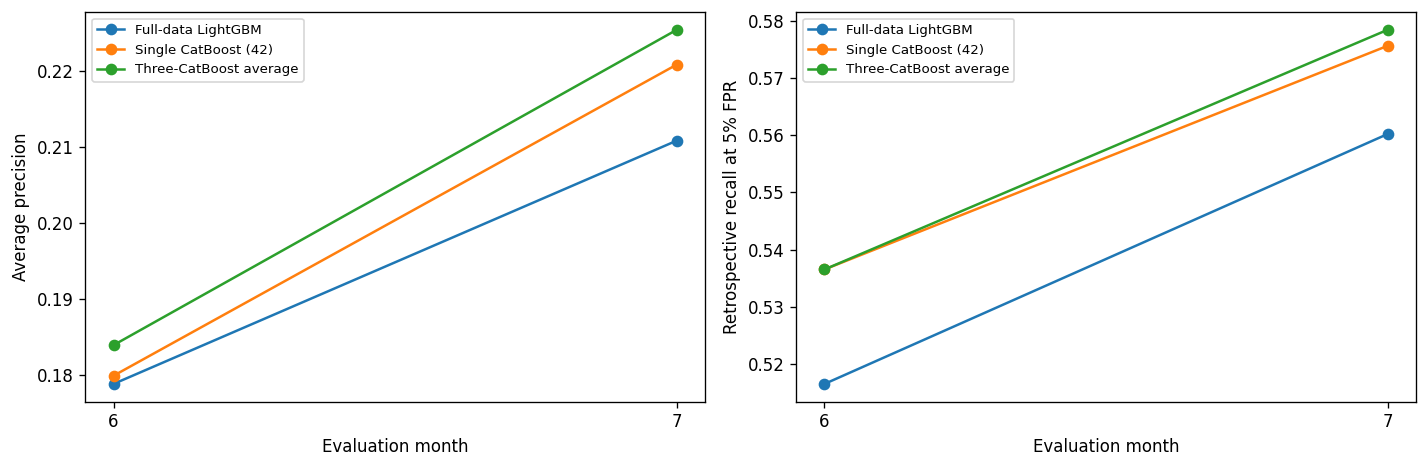

In [ ]:
holdout = read_table('10', 'static_model_metrics.csv', ['period', 'model', 'average_precision', 'retrospective_recall_at_5fpr', 'deployed_recall', 'deployed_fpr', 'deployed_tp', 'deployed_fp', 'applications'])
holdout['period'] = holdout.period.astype(str)
MODEL_ORDER = ['lightgbm_full_seed42', 'catboost_rus_seed42', 'catboost_rus_mean3']
LABELS = {'lightgbm_full_seed42': 'Full-data LightGBM', 'catboost_rus_seed42': 'Single CatBoost (42)',
          'catboost_rus_mean3': 'Three-CatBoost average'}
pooled = holdout[holdout.period.eq('6–7 pooled')].set_index('model').loc[MODEL_ORDER].reset_index()
if len(pooled) != 3:
    raise ValueError('Expected three pooled model rows from notebook 10.')
ensemble = one_row(pooled, 'model', 'catboost_rus_mean3')
lightgbm = one_row(pooled, 'model', 'lightgbm_full_seed42')
single = one_row(pooled, 'model', 'catboost_rus_seed42')
report_cols = ['period', 'model', 'average_precision', 'retrospective_recall_at_5fpr',
               'deployed_recall', 'deployed_fpr', 'deployed_precision', 'deployed_alert_rate', 'deployed_tp', 'deployed_fp']
section('10 · Static models on months 6–7',
    f"The preselected CatBoost ensemble achieved pooled AP {ensemble.average_precision:.5f} and retrospective recall@5%FPR "
    f"{ensemble.retrospective_recall_at_5fpr:.2%}. Relative to full-data LightGBM, the differences were "
    f"{ensemble.average_precision - lightgbm.average_precision:+.5f} AP and "
    f"{pp(ensemble.retrospective_recall_at_5fpr - lightgbm.retrospective_recall_at_5fpr)} recall. "
    f"Relative to single CatBoost, the AP difference was {ensemble.average_precision - single.average_precision:+.5f}. "
    'These point comparisons do not establish statistical significance or superiority at every review budget.',
    holdout[report_cols], '10_static_model_evaluation.csv')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in MODEL_ORDER:
    rows = holdout[holdout.model.eq(name) & holdout.period.isin(['6', '7'])].sort_values('period')
    for ax, col in zip(axes, ['average_precision', 'retrospective_recall_at_5fpr']):
        ax.plot(rows.period.astype(int), rows[col], marker='o', label=LABELS[name])
for ax, label in zip(axes, ['Average precision', 'Retrospective recall at 5% FPR']):
    ax.set(xlabel='Evaluation month', ylabel=label, xticks=[6, 7])
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'holdout_model_comparison.png', bbox_inches='tight')
plt.show()
report_sections.append('![Static model comparison](figures/holdout_model_comparison.png)')


## 8. Threshold drift and retraining on the reserved period

The policy comparison has a single new update opportunity: month 7. Frozen and threshold-only policies must have identical ranking metrics because their scores are identical. Threshold changes move the operating point; they do not improve model ranking.

The adaptive policies use month-6 outcomes to set month-7 cutoffs under the declared label-availability assumption. The refreshed model trains through month 5 and holds month 6 out for calibration.


## 10 · Update-policy evidence

In month 7, model refresh changed AP from 0.22543 to 0.22668 and retrospective recall@5%FPR from 57.84% to 58.40%. At their respective calibrated cutoffs, retraining versus threshold-only updating caught +20 frauds and flagged +233 legitimate applications. That operating-point difference must not be described as additional fraud capture at unchanged workload.

,month,policy,average_precision,retrospective_recall_at_5fpr,deployed_recall,deployed_fpr,deployed_precision,deployed_alert_rate,deployed_tp,deployed_fp
0,6,frozen,0.183983,0.536552,0.578621,0.064450,0.108721,0.071343,839,6878
1,6,threshold_only,0.183983,0.536552,0.578621,0.064450,0.108721,0.071343,839,6878
2,6,retrain_and_threshold,0.183983,0.536552,0.578621,0.064450,0.108721,0.071343,839,6878
3,7,frozen,0.225427,0.578431,0.593838,0.053786,0.141806,0.061749,848,5132
4,7,threshold_only,0.225427,0.578431,0.541317,0.041304,0.163980,0.048677,773,3941
5,7,retrain_and_threshold,0.226676,0.584034,0.555322,0.043746,0.159654,0.051289,793,4174


## 10 · Aggregate deployed policy behaviour

Sum month-specific decisions, then calculate pooled recall/FPR. The macro mean monthly AP is not pooled AP for a changing model.

,policy,applications,tp,fp,fn,tn,pooled_deployed_recall,pooled_deployed_fpr,pooled_deployed_precision,review_fraction,frauds_caught_per_10000,legitimate_flagged_per_10000,macro_mean_monthly_ap
0,frozen,205011,1687,12010,1191,190123,0.586171,0.059416,0.123166,0.066811,82.288267,585.822224,0.204705
1,threshold_only,205011,1612,10819,1266,191314,0.560111,0.053524,0.129676,0.060636,78.629927,527.727780,0.204705
2,retrain_and_threshold,205011,1632,11052,1246,191081,0.567060,0.054677,0.128666,0.061870,79.605485,539.093024,0.205330


## Operational meaning of threshold drift

The fixed ensemble cutoff targeted 5% FPR on month 5. Realised FPR was month 6: 6.45%; month 7: 5.38%. A cutoff selected on past labelled data does not guarantee the same future FPR. Threshold maintenance can reduce false positives but also reduce recall; assess both and the resulting review workload. This analysis concerns decision-threshold calibration, not calibration of probability estimates.

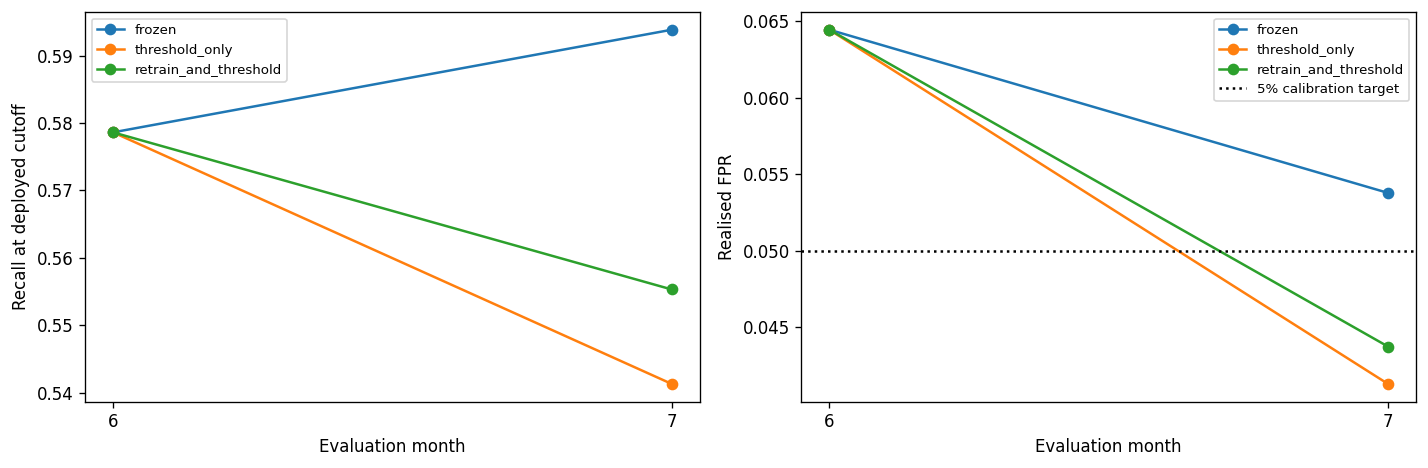

In [ ]:
policy_test = read_table('10', 'monthly_policy_metrics.csv', ['policy', 'month', 'average_precision', 'retrospective_recall_at_5fpr', 'deployed_recall', 'deployed_fpr', 'deployed_tp', 'deployed_fp'])
policy_aggregate = read_table('10', 'policy_aggregate_deployed.csv', ['policy', 'pooled_deployed_recall', 'pooled_deployed_fpr'])
thresholds = read_json('10', 'threshold_history.json')
m7 = policy_test[policy_test.month.eq(7)]
frozen = one_row(m7, 'policy', 'frozen')
threshold_only = one_row(m7, 'policy', 'threshold_only')
refreshed = one_row(m7, 'policy', 'retrain_and_threshold')
assert np.isclose(frozen.average_precision, threshold_only.average_precision)
section('10 · Update-policy evidence',
    f"In month 7, model refresh changed AP from {threshold_only.average_precision:.5f} to {refreshed.average_precision:.5f} "
    f"and retrospective recall@5%FPR from {threshold_only.retrospective_recall_at_5fpr:.2%} to {refreshed.retrospective_recall_at_5fpr:.2%}. "
    f"At their respective calibrated cutoffs, retraining versus threshold-only updating caught "
    f"{int(refreshed.deployed_tp - threshold_only.deployed_tp):+d} frauds and flagged "
    f"{int(refreshed.deployed_fp - threshold_only.deployed_fp):+d} legitimate applications. "
    'That operating-point difference must not be described as additional fraud capture at unchanged workload.',
    policy_test[['month', 'policy', 'average_precision', 'retrospective_recall_at_5fpr',
                 'deployed_recall', 'deployed_fpr', 'deployed_precision', 'deployed_alert_rate', 'deployed_tp', 'deployed_fp']],
    '10_monthly_policies.csv')
section('10 · Aggregate deployed policy behaviour',
    'Sum month-specific decisions, then calculate pooled recall/FPR. The macro mean monthly AP is not pooled AP for a changing model.',
    policy_aggregate, '10_policy_aggregate.csv')

fixed_ensemble_months = holdout[holdout.model.eq('catboost_rus_mean3') & holdout.period.isin(['6', '7'])].sort_values('period')
fpr_text = '; '.join(f"month {r.period}: {r.deployed_fpr:.2%}" for r in fixed_ensemble_months.itertuples())
section('Operational meaning of threshold drift',
    f"The fixed ensemble cutoff targeted 5% FPR on month 5. Realised FPR was {fpr_text}. "
    'A cutoff selected on past labelled data does not guarantee the same future FPR. '
    'Threshold maintenance can reduce false positives but also reduce recall; assess both and the resulting review workload. '
    'This analysis concerns decision-threshold calibration, not calibration of probability estimates.')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for policy in ['frozen', 'threshold_only', 'retrain_and_threshold']:
    rows = policy_test[policy_test.policy.eq(policy)].sort_values('month')
    for ax, col in zip(axes, ['deployed_recall', 'deployed_fpr']):
        ax.plot(rows.month, rows[col], marker='o', label=policy)
axes[1].axhline(.05, linestyle=':', color='black', label='5% calibration target')
for ax, label in zip(axes, ['Recall at deployed cutoff', 'Realised FPR']):
    ax.set(xlabel='Evaluation month', ylabel=label, xticks=[6, 7]); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES_DIR / 'threshold_and_policy_behaviour.png', bbox_inches='tight'); plt.show()
report_sections.append('![Threshold and policy behaviour](figures/threshold_and_policy_behaviour.png)')


## 9. Workload-controlled business interpretation

The scenario is **bank account-opening application review**, not payment-transaction blocking. Scores prioritise applications for investigation before approval. BAF labels do not measure whether an investigator would confirm every flagged fraud, nor how much loss a review prevents.

Exact-capacity results assume a batch is available for ranking. They hold monthly workload fixed, unlike a static score cutoff. The 1%, 2% and 5% budgets are predefined scenarios, not demonstrated optimal staffing choices.


## Review-budget scenarios for the selected ensemble

Counts sum separately ranked month-6 and month-7 queues. Precision is the share of reviews whose dataset label is fraud; recall is the share of labelled fraud captured. This is a prioritisation evaluation, not evidence of prevented losses.

,capacity,reviews,frauds_caught,legitimate_reviewed,precision,recall,frauds_caught_per_10000,legitimate_reviewed_per_10000
0,0.01,2049,633,1416,0.308931,0.219944,30.876392,69.069465
1,0.02,4099,957,3142,0.233472,0.332523,46.680422,153.260069
2,0.05,10250,1516,8734,0.147902,0.526755,73.947252,426.025921


## Report-ready capacity explanation

At the 1% monthly review budget, approximately 100 applications per 10,000 would be reviewed: 30.9 labelled fraudulent and 69.1 legitimate. This captured 22.0% of fraud with review precision 30.9%.

At the 2% monthly review budget, approximately 200 applications per 10,000 would be reviewed: 46.7 labelled fraudulent and 153.3 legitimate. This captured 33.3% of fraud with review precision 23.3%.

At the 5% monthly review budget, approximately 500 applications per 10,000 would be reviewed: 73.9 labelled fraudulent and 426.0 legitimate. This captured 52.7% of fraud with review precision 14.8%.

Choose an operating capacity based on actual staffing, customer friction and loss assumptions; this dataset alone cannot determine the optimum.

## Incremental value at identical workload

Negative differences indicate a budget where the selected ensemble catches fewer frauds than its comparator. Do not suppress those trade-offs merely because AP favours the ensemble.

,capacity,comparator,same_review_count,ensemble_additional_frauds,ensemble_change_legitimate_reviews
0,0.01,lightgbm_full_seed42,2049,26,-26
1,0.01,catboost_rus_seed42,2049,9,-9
2,0.02,lightgbm_full_seed42,4099,29,-29
3,0.02,catboost_rus_seed42,4099,8,-8
4,0.05,lightgbm_full_seed42,10250,42,-42
5,0.05,catboost_rus_seed42,10250,-4,4


## Update policies under exact review budgets

Frozen and threshold-only policies rank the same applications. Any extra fixed-budget capture from retraining reflects changed ranking, whereas a higher recall at a more permissive score cutoff can also reflect additional reviews.

,name,capacity,reviews,frauds_caught,legitimate_reviewed,precision,recall
9,frozen,0.01,2049,633,1416,0.308931,0.219944
10,frozen,0.02,4099,957,3142,0.233472,0.332523
11,frozen,0.05,10250,1516,8734,0.147902,0.526755
12,retrain_and_threshold,0.01,2049,635,1414,0.309907,0.220639
13,retrain_and_threshold,0.02,4099,963,3136,0.234935,0.334607
14,retrain_and_threshold,0.05,10250,1518,8732,0.148098,0.527450
15,threshold_only,0.01,2049,633,1416,0.308931,0.219944
16,threshold_only,0.02,4099,957,3142,0.233472,0.332523
17,threshold_only,0.05,10250,1516,8734,0.147902,0.526755


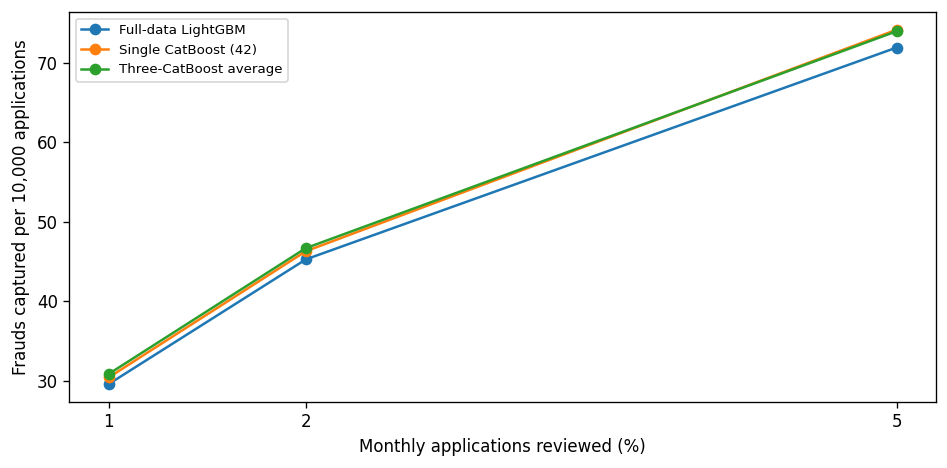

In [ ]:
capacity = read_table('10', 'review_capacity_aggregate.csv', ['comparison', 'name', 'capacity', 'reviews', 'frauds_caught', 'legitimate_reviewed', 'precision', 'recall', 'frauds_caught_per_10000', 'legitimate_reviewed_per_10000'])
static_capacity = capacity[capacity.comparison.eq('static_model')].copy()
selected_capacity = static_capacity[static_capacity.name.eq('catboost_rus_mean3')].sort_values('capacity')
section('Review-budget scenarios for the selected ensemble',
    'Counts sum separately ranked month-6 and month-7 queues. Precision is the share of reviews whose dataset label is fraud; '
    'recall is the share of labelled fraud captured. This is a prioritisation evaluation, not evidence of prevented losses.',
    selected_capacity[['capacity', 'reviews', 'frauds_caught', 'legitimate_reviewed', 'precision', 'recall',
                       'frauds_caught_per_10000', 'legitimate_reviewed_per_10000']],
    'business_review_scenarios.csv')

business_sentences = []
for r in selected_capacity.itertuples():
    actual_reviews_per_10000 = r.frauds_caught_per_10000 + r.legitimate_reviewed_per_10000
    business_sentences.append(
        f"At the {r.capacity:.0%} monthly review budget, approximately {actual_reviews_per_10000:.0f} applications "
        f"per 10,000 would be reviewed: {r.frauds_caught_per_10000:.1f} labelled fraudulent and "
        f"{r.legitimate_reviewed_per_10000:.1f} legitimate. This captured {r.recall:.1%} of fraud "
        f"with review precision {r.precision:.1%}.")
section('Report-ready capacity explanation', '\n\n'.join(business_sentences) +
    '\n\nChoose an operating capacity based on actual staffing, customer friction and loss assumptions; this dataset alone cannot determine the optimum.')

matched_rows = []
for budget in [.01, .02, .05]:
    rows = static_capacity[np.isclose(static_capacity.capacity, budget)].set_index('name')
    selected_row = rows.loc['catboost_rus_mean3']
    for reference in ['lightgbm_full_seed42', 'catboost_rus_seed42']:
        ref = rows.loc[reference]
        assert selected_row.reviews == ref.reviews
        matched_rows.append({'capacity': budget, 'comparator': reference, 'same_review_count': int(ref.reviews),
                             'ensemble_additional_frauds': int(selected_row.frauds_caught - ref.frauds_caught),
                             'ensemble_change_legitimate_reviews': int(selected_row.legitimate_reviewed - ref.legitimate_reviewed)})
matched_capacity = pd.DataFrame(matched_rows)
section('Incremental value at identical workload',
    'Negative differences indicate a budget where the selected ensemble catches fewer frauds than its comparator. '
    'Do not suppress those trade-offs merely because AP favours the ensemble.',
    matched_capacity, 'matched_review_budget_differences.csv')

policy_capacity = capacity[capacity.comparison.eq('update_policy')].copy()
section('Update policies under exact review budgets',
    'Frozen and threshold-only policies rank the same applications. Any extra fixed-budget capture from retraining reflects changed ranking, '
    'whereas a higher recall at a more permissive score cutoff can also reflect additional reviews.',
    policy_capacity[['name', 'capacity', 'reviews', 'frauds_caught', 'legitimate_reviewed', 'precision', 'recall']],
    'policy_review_budget_comparison.csv')

fig, ax = plt.subplots(figsize=(8, 4))
for name in MODEL_ORDER:
    rows = static_capacity[static_capacity.name.eq(name)].sort_values('capacity')
    ax.plot(100 * rows.capacity, rows.frauds_caught_per_10000, marker='o', label=LABELS[name])
ax.set(xlabel='Monthly applications reviewed (%)', ylabel='Frauds captured per 10,000 applications', xticks=[1, 2, 5])
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(FIGURES_DIR / 'review_capacity_tradeoff.png', bbox_inches='tight'); plt.show()
report_sections.append('![Review capacity trade-off](figures/review_capacity_tradeoff.png)')


## 10. Recommendation, limitations and team integration

This section records the selected approach and the limits of the evidence. It does not choose a new winner from the reserved-period results. Detailed SHAP, fairness and case-triage work should reference the actual model analysed; LightGBM explanations cannot be presented as CatBoost-ensemble explanations.


In [ ]:
fit_cost = read_table('10', 'model_fit_cost.csv', ['name', 'fit_seconds', 'training_rows'])
initial_fit_seconds = fit_cost.loc[fit_cost.name.str.startswith('initial_catboost'), 'fit_seconds'].sum()
refresh_fit_seconds = fit_cost.loc[fit_cost.name.str.startswith('refreshed_catboost'), 'fit_seconds'].sum()
section('Computational considerations',
    f"The three initial CatBoost fits took {initial_fit_seconds:.1f}s in total; the refreshed ensemble took {refresh_fit_seconds:.1f}s. "
    'These are observed fitting times in this run, excluding orchestration and production infrastructure. '
    'The ensemble requires three model predictions per application; inference latency was not benchmarked. '
    'Retain the single-model comparator when discussing simplicity versus predictive gain.',
    fit_cost, 'model_fit_cost.csv')

# A compact decision trail complements the detailed, split-specific tables above.
cat_family = families[families.family.eq('catboost') & families.treatment.eq('rus10')]
if len(cat_family) != 1:
    raise ValueError('Expected one selected RUS CatBoost configuration in notebook 05.')
cat_family = cat_family.iloc[0]
dev_update = policy_dev[policy_dev.evaluation_month.isin([4, 5])].pivot(
    index='evaluation_month', columns='policy', values='ap')
dev_refresh_delta = dev_update['retrain_and_threshold'] - dev_update['threshold_only']
noncontrol_adapt = adaptation[~adaptation.condition.eq('unweighted')]
findings = pd.DataFrame([
    ['03', 'Same-size recency', f'{int((matched.ap_delta_mean > 0).sum())}/{len(matched)} recent-vs-historical comparisons had positive mean AP differences',
     'All-history eligibility was retained for subsequent stages'],
    ['04', '10:1 undersampling', f'AP difference vs untreated: {rus.ap_mean - untreated.ap_mean:+.5f}; recall difference: {pp(rus.recall_at_fpr_mean - untreated.recall_at_fpr_mean)}',
     'Retained 10:1 sampling under the AP-based development policy'],
    ['05', 'Selected RUS CatBoost', f'Mean AP {cat_family.ap_mean:.5f}; mean recall@5%FPR {cat_family.recall_at_fpr_mean:.2%}',
     'Carried the selected CatBoost configuration into ensemble exploration'],
    ['06', 'Temporal stacking', f'AP difference vs CatBoost reference: {stack.ap_mean - cat_reference.ap_mean:+.5f} across {int(stack.seeds)} seed(s)',
     'Added complexity had limited demonstrated incremental value'],
    ['07', 'Temporal weighting', f'{int((noncontrol_adapt.ap_difference_from_unweighted > 0).sum())}/{len(noncontrol_adapt)} weighting conditions improved mean AP',
     'Unweighted CatBoost was retained in subsequent experiments'],
    ['08', 'Three-CatBoost average', f'Validation AP {cat_mean.average_precision:.5f}; nine-model average AP {nine.average_precision:.5f}',
     'Three-member recipe selected during development; no holdout reselection'],
    ['09', 'Development model refresh', f'AP improved in {int((dev_refresh_delta > 0).sum())}/{len(dev_refresh_delta)} update months',
     'Motivated a separately specified maintenance-policy evaluation'],
    ['10', 'Reserved-period model comparison', f'Ensemble pooled AP difference vs LightGBM: {ensemble.average_precision - lightgbm.average_precision:+.5f}',
     'Report operating-point trade-offs alongside the ranking comparison'],
    ['10', 'Reserved-period model refresh', f'Month-7 AP difference: {refreshed.average_precision - threshold_only.average_precision:+.5f}',
     'Limited evidence from one update; distinguish ranking from threshold changes'],
], columns=['notebook', 'question_or_method', 'observed_finding', 'interpretation_or_recorded_decision'])
section('Experiment findings and decision trail',
    'This table records the development sequence and evaluated outcomes. It is not a cross-stage leaderboard or a new selection rule.',
    findings, 'experiment_findings_and_decisions.csv')

section('Recommended reporting position',
    'Carry forward the **three-seed CatBoost average**, selected using validation AP, as this branch’s reporting model. '
    'Retain single CatBoost as the simpler alternative and full-data LightGBM as the baseline. '
    'Present monthly retraining as a separately evaluated maintenance policy, with only one reserved-period update opportunity. '
    'Do not claim that the ensemble or retraining policy dominates every operating point. '
    'For a review-capacity business scenario, report exact-budget capture and legitimate review workload. '
    'For an FPR-targeting scenario, report actual realised FPR alongside recall, and explain the need for monitoring as outcomes arrive.')

limitations = pd.DataFrame([
    ['Repeated validation use', 'Month 5 supported multiple development choices; gains may partly reflect validation selection.'],
    ['Prior reserved-period exposure', 'A teammate previously inspected months 6–7; disclose this rather than calling the team-wide test wholly unseen.'],
    ['Retrospective policy development', 'Notebook 09 uses configurations selected with month-5 information in earlier-month simulations.'],
    ['Label availability', 'Policy updates assume preceding-month outcomes are resolved before next-month scoring; BAF does not verify this.'],
    ['Limited update opportunities', 'Notebook 10 provides only one new policy comparison in month 7.'],
    ['Recency and sample size', 'Expanding retraining adds newer data and more data simultaneously.'],
    ['Metric trade-offs', 'AP, recall at fixed FPR and capture at fixed review budgets answer different questions.'],
    ['Uncertainty', 'Seed SD is not a confidence interval; point differences are not proof of statistical significance.'],
    ['Synthetic applications', 'BAF realism does not establish performance in a real bank or under adaptive attackers.'],
    ['Probability interpretation', 'Undersampled models’ raw scores are ranking scores, not verified population fraud probabilities.'],
    ['Business costs', 'No realised loss, review cost, investigator accuracy or intervention outcome is measured.'],
    ['Interpretability and fairness', 'Summarise teammates’ analyses with their actual model and split; do not transfer explanations between models.'],
], columns=['limitation', 'report_implication'])
section('Limitations to retain', 'These qualifications bound what the results support; they do not erase the measured comparisons.',
        limitations, 'limitations.csv')

integration = pd.DataFrame([
    ['This branch', 'Composition, imbalance, model families, stacking, adaptation, averaging, retraining and temporal evaluation', 'Use the tables in this synthesis'],
    ['Team interpretation work', 'Feature engineering, explanations, error analysis and age-group outcomes', 'Name the exact model and evaluation split; adapt to selected ensemble if claiming to explain it'],
    ['Team operational workflow', 'Review queues, case briefs, human approval and verification steps', 'Distinguish implemented code from proposed banking actions'],
    ['Shared report', 'One protocol narrative, consistent metric definitions, reproducibility and conclusions', 'Reconcile branch differences rather than mixing incompatible scores'],
], columns=['owner_or_scope', 'contribution', 'integration_action'])
section('Team handover', 'This notebook summarises this branch’s evidence. It does not claim to have rerun or verified teammates’ current analyses.',
        integration, 'team_handover.csv')


## Computational considerations

The three initial CatBoost fits took 153.0s in total; the refreshed ensemble took 188.8s. These are observed fitting times in this run, excluding orchestration and production infrastructure. The ensemble requires three model predictions per application; inference latency was not benchmarked. Retain the single-model comparator when discussing simplicity versus predictive gain.

,name,seed,training_rows,training_frauds,fit_seconds
0,lightgbm_full_seed42,42,675666,6740,56.388620
1,initial_catboost_seed_42,42,74140,6740,51.190106
2,initial_catboost_seed_43,43,74140,6740,51.329531
3,initial_catboost_seed_44,44,74140,6740,50.473791
4,refreshed_catboost_seed_42,42,89661,8151,60.852920
5,refreshed_catboost_seed_43,43,89661,8151,66.563743
6,refreshed_catboost_seed_44,44,89661,8151,61.378697


## Experiment findings and decision trail

This table records the development sequence and evaluated outcomes. It is not a cross-stage leaderboard or a new selection rule.

,notebook,question_or_method,observed_finding,interpretation_or_recorded_decision
0,03,Same-size recency,0/3 recent-vs-historical comparisons had posit...,All-history eligibility was retained for subse...
1,04,10:1 undersampling,AP difference vs untreated: +0.00654; recall d...,Retained 10:1 sampling under the AP-based deve...
2,05,Selected RUS CatBoost,Mean AP 0.19604; mean recall@5%FPR 54.59%,Carried the selected CatBoost configuration in...
3,06,Temporal stacking,AP difference vs CatBoost reference: +0.00059 ...,Added complexity had limited demonstrated incr...
4,07,Temporal weighting,0/2 weighting conditions improved mean AP,Unweighted CatBoost was retained in subsequent...
5,08,Three-CatBoost average,Validation AP 0.19791; nine-model average AP 0...,Three-member recipe selected during developmen...
6,09,Development model refresh,AP improved in 2/2 update months,Motivated a separately specified maintenance-p...
7,10,Reserved-period model comparison,Ensemble pooled AP difference vs LightGBM: +0....,Report operating-point trade-offs alongside th...
8,10,Reserved-period model refresh,Month-7 AP difference: +0.00125,Limited evidence from one update; distinguish ...


## Recommended reporting position

Carry forward the **three-seed CatBoost average**, selected using validation AP, as this branch’s reporting model. Retain single CatBoost as the simpler alternative and full-data LightGBM as the baseline. Present monthly retraining as a separately evaluated maintenance policy, with only one reserved-period update opportunity. Do not claim that the ensemble or retraining policy dominates every operating point. For a review-capacity business scenario, report exact-budget capture and legitimate review workload. For an FPR-targeting scenario, report actual realised FPR alongside recall, and explain the need for monitoring as outcomes arrive.

## Limitations to retain

These qualifications bound what the results support; they do not erase the measured comparisons.

,limitation,report_implication
0,Repeated validation use,Month 5 supported multiple development choices...
1,Prior reserved-period exposure,A teammate previously inspected months 6–7; di...
2,Retrospective policy development,Notebook 09 uses configurations selected with ...
3,Label availability,Policy updates assume preceding-month outcomes...
4,Limited update opportunities,Notebook 10 provides only one new policy compa...
5,Recency and sample size,Expanding retraining adds newer data and more ...
6,Metric trade-offs,"AP, recall at fixed FPR and capture at fixed r..."
7,Uncertainty,Seed SD is not a confidence interval; point di...
8,Synthetic applications,BAF realism does not establish performance in ...
9,Probability interpretation,Undersampled models’ raw scores are ranking sc...


## Team handover

This notebook summarises this branch’s evidence. It does not claim to have rerun or verified teammates’ current analyses.

,owner_or_scope,contribution,integration_action
0,This branch,"Composition, imbalance, model families, stacki...",Use the tables in this synthesis
1,Team interpretation work,"Feature engineering, explanations, error analy...",Name the exact model and evaluation split; ada...
2,Team operational workflow,"Review queues, case briefs, human approval and...",Distinguish implemented code from proposed ban...
3,Shared report,"One protocol narrative, consistent metric defi...",Reconcile branch differences rather than mixin...


## 11. Export the report package

The output directory contains:

- `results_synthesis.md`: report-ready narrative with tables and relative figure links.
- `tables/`: consolidated CSV tables, preserving development/holdout boundaries.
- `figures/`: three comparison figures.
- `source_inventory.csv` and `synthesis_manifest.json`: exact input paths, hashes and missing optional stages.

Review the text, add the group's dataset/method citations and connect it to the project guidelines. Keep AI-use acknowledgement consistent with your module requirements. Share this executed notebook and the small report outputs; no model or row-level data is copied.


In [ ]:
header = '# BT4012 — Results synthesis and conclusions\n\n' + (
    'Generated from explicitly selected saved runs. No fitting, tuning, threshold optimisation or model selection was performed. '
    'Development and reserved-period results are separated.\n\n')
report_path = OUTPUT_DIR / 'results_synthesis.md'
report_path.write_text(header + '\n\n'.join(report_sections) + '\n', encoding='utf-8')
pd.DataFrame(input_inventory).to_csv(OUTPUT_DIR / 'source_inventory.csv', index=False)
synthesis_manifest = {
    'status': 'complete', 'created_utc': datetime.now(timezone.utc).isoformat(),
    'selected_run_directories': {stage: str(folder) for stage, folder in runs.items()},
    'missing_optional_stages': [stage for stage in ['02'] if stage not in runs],
    'prepared_sha256': metadata['10']['prepared_sha256'],
    'input_files': input_inventory, 'prior_team_test_exposure': True,
    'reporting_model_preselected_on_validation': 'three-seed RUS CatBoost average',
    'new_models_fitted': 0, 'new_thresholds_optimised': 0, 'new_model_selection': False,
    'versions': {'numpy': np.__version__, 'pandas': pd.__version__},
}
(OUTPUT_DIR / 'synthesis_manifest.json').write_text(json.dumps(synthesis_manifest, indent=2), encoding='utf-8')
print('Report:', report_path)
print('Tables:', TABLES_DIR)
print('Figures:', FIGURES_DIR)
print('Source files recorded:', len(input_inventory))


Report: /content/drive/MyDrive/BT4012_grp_proj/results/results_synthesis/20261117T165638Z_67f7c4/results_synthesis.md
Tables: /content/drive/MyDrive/BT4012_grp_proj/results/results_synthesis/20261117T165638Z_67f7c4/tables
Figures: /content/drive/MyDrive/BT4012_grp_proj/results/results_synthesis/20261117T165638Z_67f7c4/figures
Source files recorded: 27
